# модель классификации

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
import math
import pennylane as qml
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('../data/ABC.csv')
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,1995-04-04,2.937500,2.968750,2.812500,2.953125,2.273860,40387200
1,1995-04-05,2.906250,2.968750,2.843750,2.843750,2.189643,12236800
2,1995-04-06,2.843750,2.937500,2.843750,2.890625,2.225735,3776000
3,1995-04-07,2.906250,2.906250,2.843750,2.843750,2.189643,1920800
4,1995-04-10,2.843750,2.906250,2.843750,2.875000,2.213704,2047200
...,...,...,...,...,...,...,...
6288,2020-03-26,75.870003,85.180000,75.599998,84.160004,84.160004,3263800
6289,2020-03-27,80.940002,84.059998,80.180000,81.779999,81.779999,1600500
6290,2020-03-30,83.529999,88.550003,82.440002,88.099998,88.099998,1770200
6291,2020-03-31,88.239998,90.730003,87.110001,88.500000,88.500000,2074700


In [ ]:
#low плохо показал себя
#high тоже не очень
# Adj Close хуже всех
# Volume хорошо
# Open неплохо

In [112]:

df = pd.read_csv('../data/ABC.csv')
feature_cols = ["Open", 'Volume']

# Просто превращаем каждую строчку в % изменения относительно вчерашнего дня
df_scaled = df[feature_cols].pct_change()

# Считаем лог-доходность и таргет
df['log_returns'] = np.log(df['Close'] / df['Close'].shift(1))
df['target'] = (df['log_returns'].shift(-1) > 0).astype(int)

# Склеиваем и чистим от первой пустой строки
df_scaled['target'] = df['target']
df_processed = df_scaled.dropna().reset_index(drop=True)

# Нарезаем на 64-дневные окна
window_size = 64
X_list = []
y_list = []

features_array = df_processed[feature_cols].values
targets = df_processed['target'].values

for i in range(len(df_processed) - window_size):
    X_list.append(features_array[i : i + window_size])
    y_list.append(targets[i + window_size - 1])

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.int64)

y_hot = np.eye(2)[y].astype(np.float32)
# делим на треит и тест
X_train, X_test, y_hot_train, y_hot_test = train_test_split(X, y_hot, test_size=0.2, shuffle=False)

In [113]:
# переводим их в тензоры
X_train = torch.tensor(X_train, requires_grad=True).float()
y_hot_train = torch.tensor(y_hot_train).float()
X_test = torch.tensor(X_test, requires_grad=True).float()

batch_size = 64

#объеденяем в удобный датасет
data_loader_train = torch.utils.data.DataLoader(
    list(zip(X_train, y_hot_train)), batch_size=64, shuffle=True, drop_last=True
)
data_loader_test = torch.utils.data.DataLoader(
    list(zip(X_test, y_hot_test)), batch_size=64, shuffle=True, drop_last=True
)

In [114]:
n_qubits = 8
dev = qml.device("lightning.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    qml.AngleEmbedding(inputs * torch.pi, wires=range(n_qubits), rotation="X") #переводит кубит в нужное состояние
    #qml.BasicEntanglerLayers(weights, wires=range(n_qubits)) #запутывает кубиты между собой
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(n_qubits)] #выдает число, определяющее мат ожидание класса с помощью оператора PauliZ

In [115]:
n_layers = 1
weight_shapes = {"weights": (n_layers, n_qubits)}

# квантовая модель

In [135]:
class HybridModel(torch.nn.Module):
    def __init__(self):
        super().__init__() 
        
        self.clayer_1 = nn.Linear(128, 32)
        
        self.dropout = nn.Dropout(p=0.5) # вероятность дропаута можно настроить
        
        self.qlayer_2 = nn.Linear(16, 16) 
        
        self.clayer_3 = nn.Linear(32, 64) 
        
        self.clayer_2 = nn.Linear(64, 2)
        
        

    def forward(self, x): # тензор проходит через нашу схему
        x = torch.flatten(x, start_dim=1) # выпрямляем тензор
        x = self.clayer_1(x)
        x = torch.relu(x) # активация, чтобы модель могла гнуть линии тренда
        x = self.dropout(x)
        
        
        x_1, x_2 = torch.split(x, 16, dim=1)
        
        x_2 = self.qlayer_2(x_2)
        
        x = torch.cat([x_1, x_2], dim=1)
        
        x = self.clayer_3(x)
        x = self.clayer_2(x)
        return x

model = HybridModel()

# классическая модель

In [137]:
class ClassicalModel(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.clayer_1 = nn.Linear(128, 16) 
        self.dropout = nn.Dropout(p=0.5)
        
        self.branch_1 = nn.Linear(8, 8)
        
        # заменили квантовую
        self.branch_2 = nn.Linear(8, 8)
        
        self.clayer_out = nn.Linear(16, 2)
        
    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = torch.relu(self.clayer_1(x))
        x = self.dropout(x)
        
        x_1, x_2 = torch.split(x, 8, dim=1)
        
        # Пропускаем через классические слои
        x_1 = torch.relu(self.branch_1(x_1))
        x_2 = torch.relu(self.branch_2(x_2)) 
        
        x_concat = torch.cat([x_1, x_2], dim=1)
        out = self.clayer_out(x_concat)
        return out

In [138]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.003) 
criterion = torch.nn.CrossEntropyLoss()

epochs = 40  
batch_size_real = len(data_loader_train)

criterion = torch.nn.CrossEntropyLoss()

for epoch in range(epochs):
    running_loss = 0
    for batch_X, batch_y in data_loader_train:
        optimizer.zero_grad()  # обнуляем прошлые градиенты
        

        outputs = model(batch_X) 
        
        
        loss_evaluated = criterion(outputs, batch_y)
        
        
        loss_evaluated.backward()
        optimizer.step()
    
        running_loss += loss_evaluated.item()

    y_pred_test = model(X_test)
    predictions = torch.argmax(y_pred_test, axis=1).detach().numpy()
    true_labels = torch.argmax(torch.tensor(y_hot_test), dim=1).numpy()
    correct = [1 if p == p_true else 0 for p, p_true in zip(predictions, true_labels)]
    accuracy = sum(correct) / len(correct)
    print(f"Accuracy: {accuracy * 100}%")
    
    avg_loss = running_loss / len(data_loader_train)
    print("Average loss over epoch {}: {:.4f}".format(epoch + 1, avg_loss))
    

y_pred_test = model(X_test)
predictions = torch.argmax(y_pred_test, axis=1).detach().numpy()
true_labels = torch.argmax(torch.tensor(y_hot_test), dim=1).numpy()
correct = [1 if p == p_true else 0 for p, p_true in zip(predictions, true_labels)]
accuracy = sum(correct) / len(correct)
print(f"Accuracy: {accuracy * 100}%")

Accuracy: 49.59871589085072%
Average loss over epoch 1: 0.6813
Accuracy: 50.96308186195827%
Average loss over epoch 2: 0.6781
Accuracy: 52.24719101123596%
Average loss over epoch 3: 0.6646
Accuracy: 50.24077046548957%
Average loss over epoch 4: 0.6784
Accuracy: 50.96308186195827%
Average loss over epoch 5: 0.6788
Accuracy: 49.2776886035313%
Average loss over epoch 6: 0.6628
Accuracy: 52.08667736757624%
Average loss over epoch 7: 0.6693
Accuracy: 50.24077046548957%
Average loss over epoch 8: 0.6608
Accuracy: 51.36436597110754%
Average loss over epoch 9: 0.6887
Accuracy: 49.2776886035313%
Average loss over epoch 10: 0.6717
Accuracy: 51.4446227929374%
Average loss over epoch 11: 0.6565
Accuracy: 49.35794542536115%
Average loss over epoch 12: 0.6518
Accuracy: 52.487961476725516%
Average loss over epoch 13: 0.6767
Accuracy: 51.76565008025682%
Average loss over epoch 14: 0.6617
Accuracy: 51.4446227929374%
Average loss over epoch 15: 0.6667
Accuracy: 51.36436597110754%
Average loss over epoch

# модель регрессии (ну а потом уже классификации)

In [119]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import pennylane as qml
from sklearn.model_selection import train_test_split

In [127]:
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class FinancialDataset(Dataset):
    def __init__(self, file_path, window_size=3, is_train=True, max_rows=250):
        df = pd.read_csv(file_path).head(max_rows).copy()
        
        # Расчет лог-доходности и процентных изменений
        df['log_returns'] = np.log(df['Close'] / df['Close'].shift(1))
        df['Open_pct'] = df['Open'].pct_change()
        df['Volume_pct'] = df['Volume'].pct_change()
        
        df = df.dropna().reset_index(drop=True)
        
        # Жесткое разделение выборки ДО вычисления каких-либо средних значений
        split_idx = int(len(df) * 0.8)
        train_df = df.iloc[:split_idx].reset_index(drop=True)
        test_df = df.iloc[split_idx:].reset_index(drop=True)
        
        # Извлекаем параметры нормализации ИСКЛЮЧИТЕЛЬНО из тренировочного набора
        feat_cols = ['Open_pct', 'Volume_pct']
        train_feat_mean = train_df[feat_cols].mean().values
        train_feat_std = train_df[feat_cols].std().values
        train_feat_std[train_feat_std == 0] = 1.0
        
        self.mean = train_df['log_returns'].mean()
        self.std = train_df['log_returns'].std()
        if self.std == 0: self.std = 1.0
        
        working_df = train_df if is_train else test_df
        
        # Применяем трейновые параметры к текущему датасету
        features_scaled = (working_df[feat_cols].values - train_feat_mean) / train_feat_std
        targets_scaled = (working_df['log_returns'].values - self.mean) / self.std
        
        # Нарезка временных окон
        self.X, self.y = [], []
        for i in range(len(working_df) - window_size):
            self.X.append(features_scaled[i : i + window_size])
            self.y.append(targets_scaled[i + window_size])
            
        self.X = torch.tensor(np.array(self.X), dtype=torch.float32)
        self.y = torch.tensor(np.array(self.y), dtype=torch.float32).reshape(-1, 1)
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [128]:
n_qubits = 4 
dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev, interface="torch")
def qnode(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="X")
    qml.BasicEntanglerLayers(weights, wires=range(n_qubits))
    return [qml.expval(qml.PauliZ(wires=i)) for i in range(n_qubits)]

n_layers = 2
weight_shapes = {"weights": (n_layers, n_qubits)}
qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)

# квантавая модель

In [129]:
class QuantumTransformerModel(nn.Module):
    def __init__(self, use_quantum=True, input_dim=6):
        super().__init__()
        self.use_quantum = use_quantum
        
        self.linear_in = nn.Linear(input_dim, 4)
        if self.use_quantum:
            self.quantum_branch = qlayer
        else:
            self.quantum_branch = nn.Linear(4, 4)
            
        self.linear_out = nn.Linear(4, 1, bias=True)
        
        # Инициализируем веса финального слоя нулями для одинакового старта
        nn.init.zeros_(self.linear_out.weight)
        nn.init.zeros_(self.linear_out.bias)
        
    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = self.linear_in(x)
        if self.use_quantum:
            x = torch.clamp(x, -1.0, 1.0) * torch.pi
            x = self.quantum_branch(x)
        else:
            x = torch.clamp(x, -1.0, 1.0)
            x = self.quantum_branch(x)
        return self.linear_out(x)

In [130]:
# обучаем

In [131]:
class ComparativeTrainer:
    def __init__(self, train_loader, test_loader, dataset_mean, dataset_std):
        self.train_loader = train_loader
        self.test_loader = test_loader
        self.mean = dataset_mean
        self.std = dataset_std
        self.criterion = nn.MSELoss()

    def train_and_evaluate_by_epochs(self, model, epochs=40, lr=0.002, name="Модель"):
        optimizer = optim.Adam(model.parameters(), lr=lr)
        train_losses = []
        test_mses = [] 
        test_accuracies = [] 
        
        print(f"\n Запуск честного обучения для: {name}...")
        
        for epoch in range(epochs):
            model.train()
            epoch_train_loss = 0.0
            for inputs, targets in self.train_loader:
                optimizer.zero_grad()
                outputs = model(inputs)
                loss = self.criterion(outputs, targets)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                epoch_train_loss += loss.item()
            
            avg_train_loss = epoch_train_loss / len(self.train_loader)
            train_losses.append(avg_train_loss)
            
            # Валидация в конце каждой эпохи
            model.eval()
            epoch_test_preds = []
            epoch_test_actuals = []
            
            with torch.no_grad():
                for inputs, targets in self.test_loader:
                    outputs = model(inputs)
                    epoch_test_preds.extend(outputs.numpy().flatten())
                    epoch_test_actuals.extend(targets.numpy().flatten())
            
            # Честная денормализация обратно в масштаб рынка
            real_act = np.array(epoch_test_actuals) * self.std + self.mean
            real_prd = np.array(epoch_test_preds) * self.std + self.mean
            
            # Расчет MSE
            epoch_real_mse = np.mean((real_act - real_prd) ** 2)
            test_mses.append(epoch_real_mse)
            
            # Расчет Directional Accuracy (угадывание знака тренда)
            correct_directions = (real_act * real_prd) > 0
            epoch_accuracy = np.mean(correct_directions) * 100.0
            test_accuracies.append(epoch_accuracy)
            
            if (epoch + 1) % 5 == 0 or epoch == 0:
                print(f"  Эпоха [{epoch+1}/{epochs}] -> Тр.Loss: {avg_train_loss:.4f} | Честный Тест.MSE: {epoch_real_mse:.6f} | Направл.Accuracy: {epoch_accuracy:.2f}%")
                
        return train_losses, test_mses, test_accuracies, real_act, real_prd

 Шаг 1. Загрузка изолированных датасетов (Защита от Data Leakage)...

 Запуск честного обучения для: Честный Квантовый Гибрид...
  Эпоха [1/35] -> Тр.Loss: 0.9915 | Честный Тест.MSE: 0.000367 | Направл.Accuracy: 46.81%
  Эпоха [5/35] -> Тр.Loss: 0.9817 | Честный Тест.MSE: 0.000364 | Направл.Accuracy: 44.68%
  Эпоха [10/35] -> Тр.Loss: 0.9622 | Честный Тест.MSE: 0.000358 | Направл.Accuracy: 48.94%
  Эпоха [15/35] -> Тр.Loss: 0.9445 | Честный Тест.MSE: 0.000357 | Направл.Accuracy: 51.06%
  Эпоха [20/35] -> Тр.Loss: 0.9325 | Честный Тест.MSE: 0.000357 | Направл.Accuracy: 57.45%
  Эпоха [25/35] -> Тр.Loss: 0.9246 | Честный Тест.MSE: 0.000357 | Направл.Accuracy: 59.57%
  Эпоха [30/35] -> Тр.Loss: 0.9189 | Честный Тест.MSE: 0.000356 | Направл.Accuracy: 59.57%
  Эпоха [35/35] -> Тр.Loss: 0.9142 | Честный Тест.MSE: 0.000355 | Направл.Accuracy: 57.45%
--------------------------------------------------

 Запуск честного обучения для: Честная Чистая Классика...
  Эпоха [1/35] -> Тр.Loss: 0.9927 |

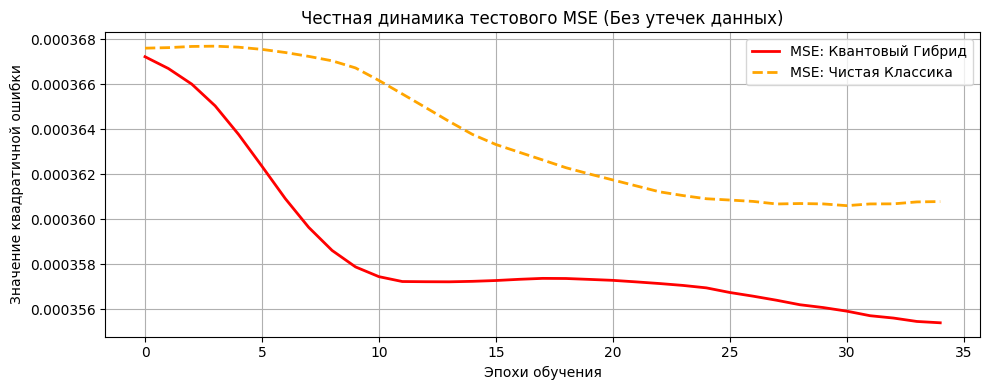

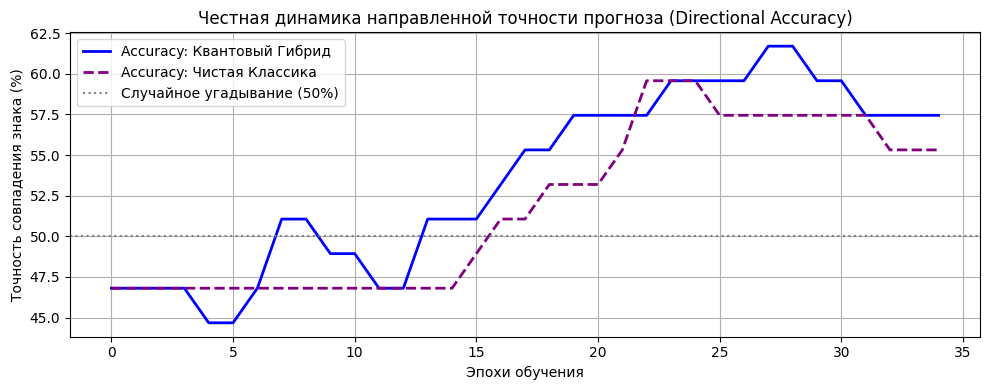

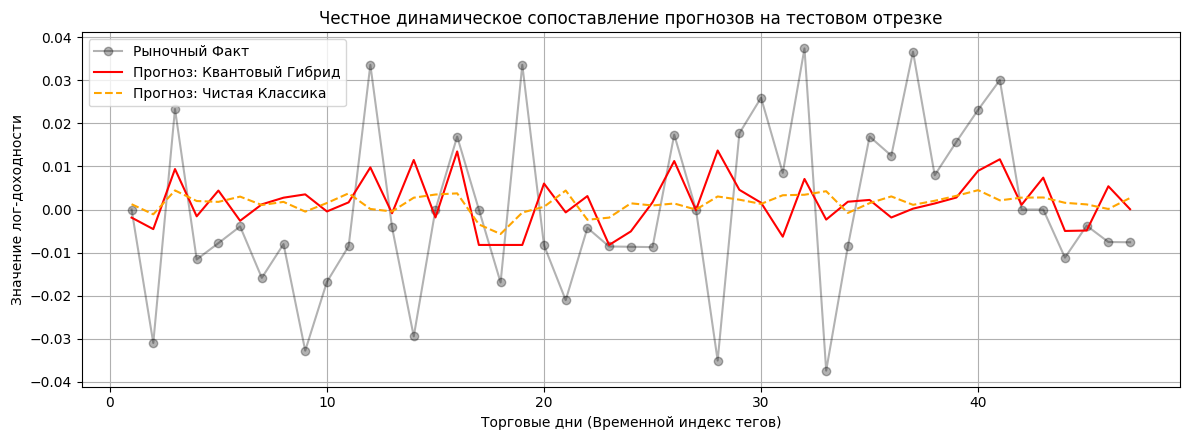

In [134]:
if __name__ == "__main__":
    seed_everything(42) 
    
    FILE_PATH = '../data/ABC.csv' # Замени на имя своего файла
    TOTAL_ROWS = 250     
    WINDOW_SIZE = 3      
    BATCH_SIZE = 16 
    EPOCHS = 35 
    LEARNING_RATE = 0.002 
    
    print(" Шаг 1. Загрузка изолированных датасетов (Защита от Data Leakage)...")
    train_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=True, max_rows=TOTAL_ROWS)
    test_dataset = FinancialDataset(FILE_PATH, window_size=WINDOW_SIZE, is_train=False, max_rows=TOTAL_ROWS)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
    
    trainer = ComparativeTrainer(train_loader, test_loader, train_dataset.mean, train_dataset.std)
    input_dim_computed = WINDOW_SIZE * 2
    
    # 1. Обучение Квантового Гибрида
    seed_everything(42)
    hybrid_model = QuantumTransformerModel(use_quantum=True, input_dim=input_dim_computed)
    _, hybrid_test_mses, hybrid_accs, real_actuals, final_hybrid_preds = trainer.train_and_evaluate_by_epochs(
        hybrid_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Честный Квантовый Гибрид"
    )
    
    print("-" * 50)
    
    # 2. Обучение Чистой Классики
    seed_everything(42)
    classic_model = QuantumTransformerModel(use_quantum=False, input_dim=input_dim_computed)
    _, classic_test_mses, classic_accs, _, final_classic_preds = trainer.train_and_evaluate_by_epochs(
        classic_model, epochs=EPOCHS, lr=LEARNING_RATE, name="Честная Чистая Классика"
    )
    
    # Печать итогового резюме в консоль
    
    print(" РЕЗУЛЬТАТЫ ПОСЛЕ ПОЛНОЙ КОРРЕКЦИИ DATA LEAKAGE:")
    
    print(f"  -> Итоговый Тестовый MSE (Кванты):  {hybrid_test_mses[-1]:.6f}")
    print(f"  -> Итоговый Тестовый MSE (Классика): {classic_test_mses[-1]:.6f}")
    print("----------------------------------------------------")
    print(f"  Честная Финальная Accuracy (Кванты):    {hybrid_accs[-1]:.2f}%")
    print(f"  Честная Финальная Accuracy (Классика):   {classic_accs[-1]:.2f}%")
    print("====================================================\n")
    # ГРАФИК №1: Динамика изменения метрики Ошибки (MSE) по эпохам
    plt.figure(figsize=(10, 4))
    plt.plot(hybrid_test_mses, label="MSE: Квантовый Гибрид", color="red", linewidth=2)
    plt.plot(classic_test_mses, label="MSE: Чистая Классика", color="orange", linestyle="--", linewidth=2)
    plt.title("Честная динамика тестового MSE (Без утечек данных)")
    plt.xlabel("Эпохи обучения")
    plt.ylabel("Значение квадратичной ошибки")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ГРАФИК №2: Динамика изменения Точности угадывания направления (Accuracy в %)
    plt.figure(figsize=(10, 4))
    plt.plot(hybrid_accs, label="Accuracy: Квантовый Гибрид", color="blue", linewidth=2)
    plt.plot(classic_accs, label="Accuracy: Чистая Классика", color="purple", linestyle="--", linewidth=2)
    # Горизонтальная линия случайного блуждания рынка (50/50)
    plt.axhline(y=50.0, color='gray', linestyle=':', label='Случайное угадывание (50%)')
    plt.title("Честная динамика направленной точности прогноза (Directional Accuracy)")
    plt.xlabel("Эпохи обучения")
    plt.ylabel("Точность совпадения знака (%)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ГРАФИК №3: Визуальное сравнение предсказанных линий доходности с фактом рынка
    plt.figure(figsize=(12, 4.5))
    view_days = min(50, len(real_actuals)) # Смотрим на последние 50 дней теста
    days_axis = np.arange(1, view_days + 1)
    
    plt.plot(days_axis, real_actuals[-view_days:], label="Рыночный Факт", color="black", marker='o', alpha=0.3)
    plt.plot(days_axis, final_hybrid_preds[-view_days:], label="Прогноз: Квантовый Гибрид", color="red", linestyle="-")
    plt.plot(days_axis, final_classic_preds[-view_days:], label="Прогноз: Чистая Классика", color="orange", linestyle="--")
    plt.title("Честное динамическое сопоставление прогнозов на тестовом отрезке")
    plt.xlabel("Торговые дни (Временной индекс тегов)")
    plt.ylabel("Значение лог-доходности")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


💰 ФИНАНСОВЫЕ РЕЗУЛЬТАТЫ СИМУЛЯЦИИ ТОРГОВЛИ (В ПЛЮС):
  📈 Пассивная стратегия (Купил и держи маркет): -0.00%
  🤖 Торговля по КВАНТОВОМУ ГИБРИДУ:            28.26%
  ⚙️ Торговля по ЧИСТОЙ КЛАССИКЕ:              15.63%



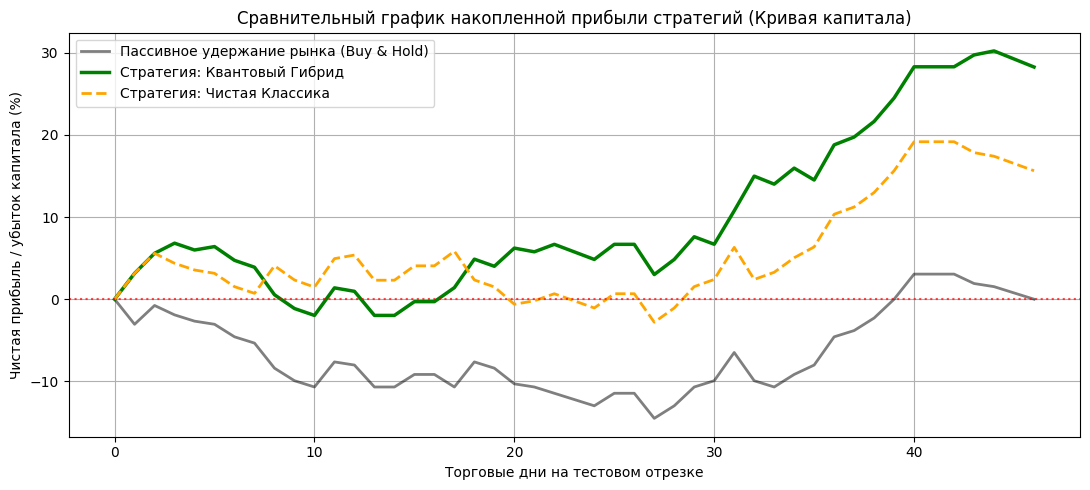

In [133]:
# ====================================================================
# 7. БЛОК СИМУЛЯЦИИ ТОРГОВЛИ И РАСЧЕТА ПРИБЫЛИ (BACKTESTING)
# ====================================================================
def run_trading_backtest(real_actuals, hybrid_preds, classic_preds):
    """
    Симулирует торговлю на тестовом отрезке рынка.
    real_actuals: реальные лог-доходности рынка
    hybrid_preds: прогнозы квантовой модели
    classic_preds: прогнозы классической модели
    """
    # Создаем DataFrame для удобства расчета торговых метрик
    df_trade = pd.DataFrame({
        'market_returns': real_actuals,
        'hybrid_pred': hybrid_preds,
        'classic_pred': classic_preds
    })
    
    # Генерируем торговые сигналы: +1 (Long), -1 (Short)
    # Если прогноз > 0, покупаем. Если < 0, продаем в шорт.
    df_trade['hybrid_signal'] = np.where(df_trade['hybrid_pred'] > 0, 1, -1)
    df_trade['classic_signal'] = np.where(df_trade['classic_pred'] > 0, 1, -1)
    
    # Считаем доходность стратегий на каждый день
    # Мы умножаем сигнал текущего дня на реальную доходность этого дня
    df_trade['hybrid_strategy_returns'] = df_trade['hybrid_signal'] * df_trade['market_returns']
    df_trade['classic_strategy_returns'] = df_trade['classic_signal'] * df_trade['market_returns']
    
    # Переводим лог-доходности в кумулятивную (накопленную) реальную прибыль.
    # Формула: exp(sum(log_returns)) - 1, чтобы получить чистый прирост капитала в процентах.
    df_trade['market_cum'] = (np.exp(df_trade['market_returns'].cumsum()) - 1) * 100.0
    df_trade['hybrid_cum'] = (np.exp(df_trade['hybrid_strategy_returns'].cumsum()) - 1) * 100.0
    df_trade['classic_cum'] = (np.exp(df_trade['classic_strategy_returns'].cumsum()) - 1) * 100.0
    
    # Выводим текстовые финансовые результаты в консоль
    print("\n====================================================")
    print("💰 ФИНАНСОВЫЕ РЕЗУЛЬТАТЫ СИМУЛЯЦИИ ТОРГОВЛИ (В ПЛЮС):")
    print("====================================================")
    print(f"  📈 Пассивная стратегия (Купил и держи маркет): {df_trade['market_cum'].iloc[-1]:.2f}%")
    print(f"  🤖 Торговля по КВАНТОВОМУ ГИБРИДУ:            {df_trade['hybrid_cum'].iloc[-1]:.2f}%")
    print(f"  ⚙️ Торговля по ЧИСТОЙ КЛАССИКЕ:              {df_trade['classic_cum'].iloc[-1]:.2f}%")
    print("====================================================\n")
    
    # Строим итоговый финансовый график кривой капитала (Equity Curve)
    plt.figure(figsize=(11, 5))
    plt.plot(df_trade['market_cum'].values, label="Пассивное удержание рынка (Buy & Hold)", color="black", alpha=0.5, linewidth=2)
    plt.plot(df_trade['hybrid_cum'].values, label="Стратегия: Квантовый Гибрид", color="green", linewidth=2.5)
    plt.plot(df_trade['classic_cum'].values, label="Стратегия: Чистая Классика", color="orange", linestyle="--", linewidth=2)
    
    # Линия нулевой прибыли
    plt.axhline(y=0.0, color='red', linestyle=':', alpha=0.7)
    
    plt.title("Сравнительный график накопленной прибыли стратегий (Кривая капитала)")
    plt.xlabel("Торговые дни на тестовом отрезке")
    plt.ylabel("Чистая прибыль / убыток капитала (%)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Чтобы запустить этот блок, просто вставь вызов этой функции в самый конец твоего кода 
# (внутрь блока if __name__ == "__main__":), передав туда результаты обучения:
run_trading_backtest(real_actuals, final_hybrid_preds, final_classic_preds)